<a href="https://colab.research.google.com/github/nguyentuanphong0510/Machine-Learning/blob/main/BTVN_Buoi01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Độ nhiễu (flip_y) = 0.00  --> Độ chính xác (Accuracy) = 0.8300
Độ nhiễu (flip_y) = 0.05  --> Độ chính xác (Accuracy) = 0.8300
Độ nhiễu (flip_y) = 0.10  --> Độ chính xác (Accuracy) = 0.8150
Độ nhiễu (flip_y) = 0.20  --> Độ chính xác (Accuracy) = 0.7500
Độ nhiễu (flip_y) = 0.30  --> Độ chính xác (Accuracy) = 0.7000
Độ nhiễu (flip_y) = 0.40  --> Độ chính xác (Accuracy) = 0.7150


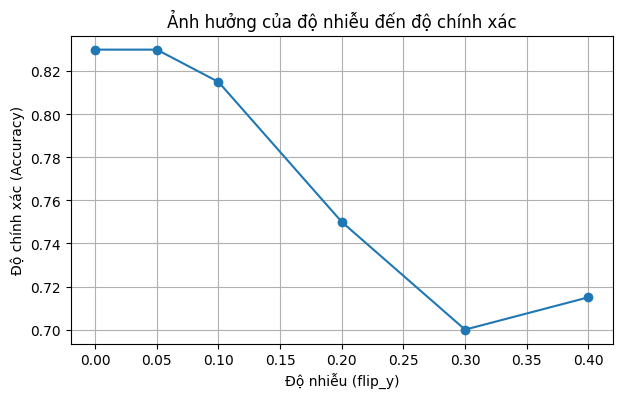

In [2]:
# Bài 1. Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô hình
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4]
accuracies = []

for noise in noise_levels:
    # Sinh dữ liệu phân loại nhị phân, tăng flip_y để mô phỏng độ nhiễu nhãn
    X, y = make_classification(
        n_samples=1000,
        n_features=10,
        n_informative=6,
        n_redundant=2,
        flip_y=noise,
        random_state=42
    )

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LogisticRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"Độ nhiễu (flip_y) = {noise:.2f}  --> Độ chính xác (Accuracy) = {acc:.4f}")

# Vẽ biểu đồ trực quan
plt.figure(figsize=(7, 4))
plt.plot(noise_levels, accuracies, marker='o')
plt.title("Ảnh hưởng của độ nhiễu đến độ chính xác")
plt.xlabel("Độ nhiễu (flip_y)")
plt.ylabel("Độ chính xác (Accuracy)")
plt.grid(True)
plt.show()

In [3]:
# Bài 2. Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,… thay vì 0.5) và quan sát sự thay đổi trong kết quả dự đoán.
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Sinh dữ liệu
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    weights=[0.7, 0.3],  # hơi mất cân bằng lớp để thấy rõ tác động của ngưỡng
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

# Lấy xác suất dự đoán thuộc lớp 1
y_prob = model.predict_proba(X_test)[:, 1]

thresholds = [0.3, 0.5, 0.6, 0.7, 0.8]

print(f"{'Ngưỡng':<8} | {'Số dự đoán=1':<12} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1':<10}")
print("-" * 76)

for th in thresholds:
    y_pred_th = (y_prob >= th).astype(int)
    acc = accuracy_score(y_test, y_pred_th)
    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)
    count_pos = np.sum(y_pred_th == 1)
    print(f"{th:<8.2f} | {count_pos:<12d} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")

# Xem chi tiết ma trận nhầm lẫn ở ngưỡng 0.7
print("\nConfusion Matrix tại ngưỡng 0.7:")
print(confusion_matrix(y_test, (y_prob >= 0.7).astype(int)))

Ngưỡng   | Số dự đoán=1 | Accuracy   | Precision  | Recall     | F1        
----------------------------------------------------------------------------
0.30     | 84           | 0.7750     | 0.5357     | 0.8824     | 0.6667    
0.50     | 58           | 0.8150     | 0.6207     | 0.7059     | 0.6606    
0.60     | 44           | 0.8150     | 0.6591     | 0.5686     | 0.6105    
0.70     | 38           | 0.8250     | 0.7105     | 0.5294     | 0.6067    
0.80     | 25           | 0.8000     | 0.7200     | 0.3529     | 0.4737    

Confusion Matrix tại ngưỡng 0.7:
[[138  11]
 [ 24  27]]


Kích thước dữ liệu: (506, 14)
      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        b  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  

Mean Squared Error (MSE): 24.2911
Root Mean Squared Error (RMSE): 4.9286
R² Score: 0.6688


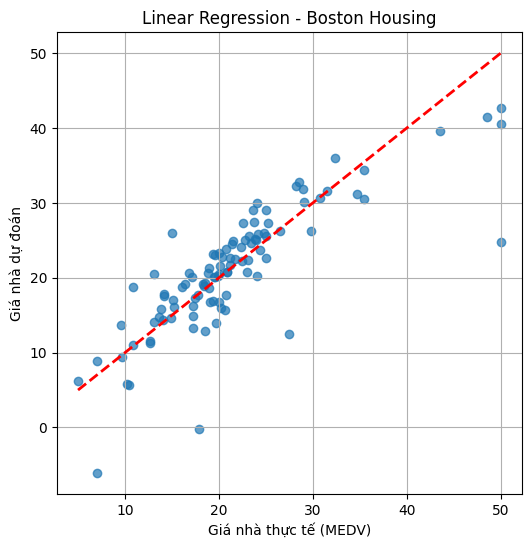

In [4]:
#  Bài 3. Hồi quy tuyến tính với tập dữ liệu giá nhà ở
#   Mô tả: Sử dụng thuật toán Linear Regression để dự đoán giá nhà dựa trên một số thuộc tính.
#   Yêu cầu
#   Tải tập dữ liệu Boston Housing từ sklearn.datasets (có thể tải từ kaggle).
# - Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra.
# - Huấn luyện mô hình hồi quy tuyến tính trên tập huấn luyện và dự đoán trên tập kiểm tra.
# - Tính toán các chỉ số đánh giá: MSE (Mean Squared Error) và R² score cho tập kiểm tra.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu Boston Housing
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(url)

# Nếu bạn tải file từ Kaggle và upload lên Colab, dùng dòng dưới thay cho url:
# df = pd.read_csv("BostonHousing.csv")

print("Kích thước dữ liệu:", df.shape)
print(df.head())

# Kiểm tra giá trị thiếu (nếu có thì điền trung vị)
df = df.dropna()

# Cột mục tiêu thường là 'medv' (hoặc 'MEDV' tùy file)
target_col = 'medv' if 'medv' in df.columns else 'MEDV'
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Chia tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Huấn luyện mô hình Linear Regression (kèm chuẩn hóa đặc trưng)
model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# 4. Đánh giá bằng MSE và R² score
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

# Vẽ biểu đồ so sánh giá thực tế và giá dự đoán
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Giá nhà thực tế (MEDV)")
plt.ylabel("Giá nhà dự đoán")
plt.title("Linear Regression - Boston Housing")
plt.grid(True)
plt.show()